# Modelo de propensión de compra
**Objetivo:** predecir si un cliente comprará la categoría en una visita. Este notebook cubre los pasos 1 a 5: fijar qué predecimos y con qué información, verificar que los datos sean coherentes, aplicar la limpieza mínima justificada y reservar validación y prueba **antes** del EDA detallado y del modelado.

**Entrada:** `compras_data.csv` o el ZIP original. El notebook se ejecuta de principio a fin en orden.

## Paso 1. Definición del problema
| Elemento | Decisión |
|---|---|
| Unidad de análisis | Una visita de un cliente (cliente × día) |
| Target del modelo 1 (incidencia) | `incidencia_compra`: 1 si compra **la categoría** (cualquier marca) durante la visita |
| Target del modelo 2 (elección de marca) | `id_marca` (1–5), solo en las visitas con compra |
| Salida | Para cada visita y cada marca *k*: P(compra marca *k*) = P(compra) × P(marca *k* \| compra) |
| Momento de predicción | Inicio del día de la visita |
| Información disponible | Perfil del cliente, precios y promociones del día, historial hasta la visita **anterior** |
| Información **no** disponible | `cantidad` e `id_marca` de la visita actual: son el resultado, no predictores |
| Uso de negocio | Saber a quién activar, con qué producto y con qué precio o promoción (pricing) |

**Objetivo de modelamiento:** estimar, para cada visita de un cliente, la probabilidad de que compre cada marca de la categoría. Los datos no tienen SKU, así que el “determinado producto” del enunciado es una marca. La probabilidad se descompone de forma exacta (probabilidad total) en dos modelos:
- **Modelo 1, incidencia:** ¿comprará en esta visita? Depende sobre todo del historial del cliente y del precio de la categoría.
- **Modelo 2, elección de marca:** si compra, ¿qué marca elige? Depende de la lealtad y del precio y la promoción de cada marca frente a las demás.

Separar las dos decisiones da probabilidades coherentes (la suma de las 5 marcas es la probabilidad de compra). También evita modelos binarios con muy pocos positivos (la marca 3 aparece en el 1,4 % de las visitas) y permite medir elasticidades propias y cruzadas por marca.

**Fuera del alcance:** no se predice si el cliente visitará la tienda, porque solo hay datos de visitas; la propensión es *condicionada a la visita*. Tampoco se predice la cantidad.

In [15]:
import warnings
from pathlib import Path
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import seaborn as sns
import lightgbm as lgb
import shap
from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             log_loss, roc_auc_score, silhouette_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


datos=pd.read_csv("compras_data.csv")

TARGET = "incidencia_compra"
PRECIOS = [f"precio_marca_{i}" for i in range(1, 6)]
PROMOS = [f"promo_marca_{i}" for i in range(1, 6)]
PERFIL = ["genero", "estado_civil", "edad", "nivel_educacion", "ingreso_anual", "ocupacion"]


## Paso 2. Auditoría: verificaciones de integridad
Complementan la auditoría del EDA: rangos válidos, variables que deberían ser constantes y coherencia entre columnas. Si alguna falla, se corrige antes de continuar.

In [16]:
ordenado = datos.sort_values(["id", "dia_visita"]).reset_index(drop=True)
anterior = ordenado.groupby("id")[[TARGET, "id_marca"]].shift().fillna(0)
anterior
checks = {
    "Edad entre 18 y 100": datos.edad.between(18, 100).all(),
    "Ingreso positivo": datos.ingreso_anual.gt(0).all(),
    "Precios positivos": datos[PRECIOS].gt(0).all().all(),
    "Promociones binarias": datos[PROMOS].isin([0, 1]).all().all(),
    "Compra binaria": datos[TARGET].isin([0, 1]).all(),
    "Marca en 0..5": datos.id_marca.between(0, 5).all(),
    "Compra <=> cantidad > 0": datos[TARGET].eq(datos.cantidad.gt(0).astype(int)).all(),
    "Compra <=> marca > 0": datos[TARGET].eq(datos.id_marca.gt(0).astype(int)).all(),
    "Perfil constante por cliente": datos.groupby("id")[PERFIL].nunique().le(1).all().all(),
    "Un precio/promo por día (nivel tienda)": datos.groupby("dia_visita")[PRECIOS + PROMOS].nunique().le(1).all().all(),
    "Historial = visita anterior": (
        ordenado.ultima_cantidad_comprada.eq(anterior[TARGET]).all()
        and ordenado.ultima_marca_comprada.eq(anterior.id_marca).all()
    ),
}
checks = pd.Series(checks, name="Cumple")
display(checks.to_frame())
assert checks.all(), "Revisar la verificación fallida antes de continuar"

,Cumple
Edad entre 18 y 100,True
Ingreso positivo,True
Precios positivos,True
Promociones binarias,True
Compra binaria,True
Marca en 0..5,True
Compra <=> cantidad > 0,True
Compra <=> marca > 0,True
Perfil constante por cliente,True
Un precio/promo por día (nivel tienda),True


**Hallazgo → decisión:** todas las verificaciones se cumplen; no hay registros que corregir ni eliminar.

Dos hallazgos estructurales condicionan el resto del trabajo:
- **El perfil es constante por cliente.** Hay 500 perfiles, no 58 693. Analizar el perfil a nivel visita sobrepondera a quienes visitan más; los análisis de perfil se harán a nivel cliente.
- **El precio y la promoción son iguales para todos los clientes en un mismo día.** La variación de precio es temporal (730 escenarios), no entre clientes. Por eso el efecto precio puede mezclarse con tendencia o estacionalidad, y la elasticidad se interpretará como asociación condicionada, no como efecto causal.

## Paso 3. Limpieza y partición
### 3.1 Limpieza justificada
| Columna | Acción | Motivo |
|---|---|---|
| `tamanio_ciudad` | Eliminar | Instrucción del diccionario |
| `cantidad`, `id_marca` | Conservar fuera de los predictores | Son el resultado de la visita (fuga). `id_marca` es la target del modelo 2; `cantidad` se reserva para el valor |
| `ultima_cantidad_comprada` | Renombrar a `compro_visita_anterior` | Es un indicador 0/1 de compra en la visita previa, no una cantidad |
| `ultima_marca_comprada` | Renombrar a `marca_visita_anterior` | Es la marca de la visita previa (0 si no compró), no la última marca comprada |
| `genero`, `estado_civil`, `nivel_educacion`, `ocupacion` | Mantener los códigos; codificar en el paso 5 | Los códigos no tienen significado documentado; no se inventan etiquetas |
| Valores extremos | Conservar | Son plausibles y no hay evidencia de error |
| Filas | No se elimina ninguna | Sin nulos, duplicados ni incoherencias |

In [17]:
datos = (
    datos.drop(columns="tamanio_ciudad")
         .rename(columns={
             "ultima_cantidad_comprada": "compro_visita_anterior",
             "ultima_marca_comprada": "marca_visita_anterior",
         })
         .sort_values(["id", "dia_visita"])
         .reset_index(drop=True)
)

COLUMNAS_FUGA = ["cantidad", "id_marca"]

# Valores extremos a nivel cliente: el perfil es constante y no debe ponderarse por visitas.
clientes = datos.groupby("id").agg(
    ingreso_anual=("ingreso_anual", "first"),
    edad=("edad", "first"),
    visitas=("dia_visita", "size"),
)
def fuera_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())

display(pd.DataFrame({
    "Clientes fuera de 1,5·IQR": clientes.apply(fuera_iqr),
    "Mínimo": clientes.min(),
    "Mediana": clientes.median(),
    "Máximo": clientes.max(),
}))

,"Clientes fuera de 1,5·IQR",Mínimo,Mediana,Máximo
ingreso_anual,22,38247,117804.5,309364
edad,3,18,36.0,75
visitas,25,72,114.0,358


**Hallazgo → decisión:** los extremos de ingreso, edad y número de visitas corresponden a clientes plausibles (por ejemplo, alto ingreso o visitas muy frecuentes). Se conservan; si afectan a modelos sensibles a la escala, se tratarán con transformaciones ajustadas solo con entrenamiento (por ejemplo, logaritmo del ingreso), no eliminándolos.

### 3.2 Partición temporal
El modelo se usará para predecir visitas **futuras** de clientes que ya conocemos. La partición respeta ese orden: entrenamiento con el pasado, validación para elegir modelo e hiperparámetros, y prueba para la estimación final. Se usan bloques de 90 días, como en el EDA.

,dia_inicio,dia_fin,visitas,clientes,tasa_compra,pct_visitas
particion,,,,,,
entrenamiento,1,550,45497,500,24.98,77.52
validacion,551,640,6544,500,24.98,11.15
prueba,641,730,6652,500,24.62,11.33


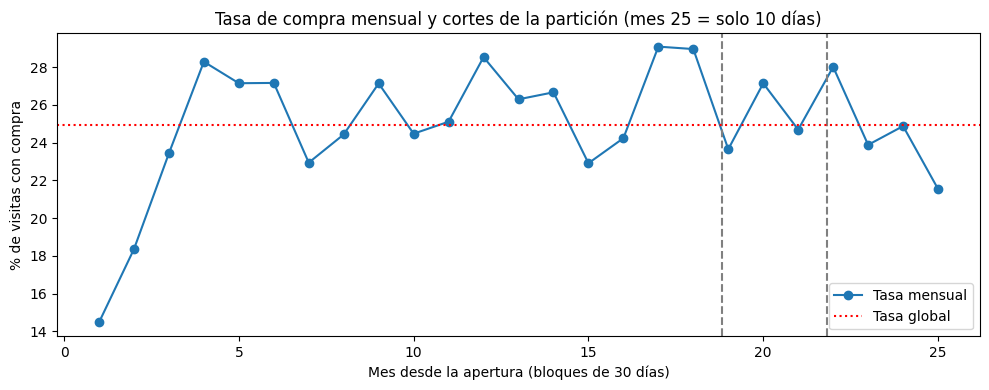

In [18]:
CORTE_VALIDACION = 550   # entrenamiento: días 1–550
CORTE_PRUEBA = 640       # validación: 551–640 | prueba: 641–730

datos["particion"] = np.select(
    [datos.dia_visita <= CORTE_VALIDACION, datos.dia_visita <= CORTE_PRUEBA],
    ["entrenamiento", "validacion"],
    default="prueba",
)
orden = ["entrenamiento", "validacion", "prueba"]
resumen = (
    datos.groupby("particion")
         .agg(dia_inicio=("dia_visita", "min"), dia_fin=("dia_visita", "max"),
              visitas=("id", "size"), clientes=("id", "nunique"),
              tasa_compra=(TARGET, "mean"))
         .reindex(orden)
)
resumen["pct_visitas"] = 100 * resumen.visitas / len(datos)
resumen["tasa_compra"] *= 100
display(resumen.round(2))

mensual = datos.assign(mes=(datos.dia_visita - 1) // 30 + 1).groupby("mes")[TARGET].mean().mul(100)
ax = mensual.plot(marker="o", figsize=(10, 4), label="Tasa mensual")
for corte in (CORTE_VALIDACION, CORTE_PRUEBA):
    ax.axvline(corte / 30 + 0.5, color="grey", linestyle="--")
ax.axhline(datos[TARGET].mean() * 100, color="red", linestyle=":", label="Tasa global")
ax.set(xlabel="Mes desde la apertura (bloques de 30 días)", ylabel="% de visitas con compra",
       title="Tasa de compra mensual y cortes de la partición (mes 25 = solo 10 días)")
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
# Tasa de compra según cuántas visitas previas tiene el cliente (todo el histórico, solo descriptivo)
visitas_previas = datos.groupby("id").cumcount().clip(upper=10)
display(datos.groupby(visitas_previas)[TARGET].mean().mul(100).round(1)
             .rename("% compra").rename_axis("visitas previas (10 = 10 o más)").to_frame().T)

visitas previas (10 = 10 o más),0,1,2,3,4,5,6,7,8,9,10
% compra,10.6,8.4,15.8,14.4,11.4,15.6,16.2,17.6,16.8,20.0,25.9


**Hallazgo → decisión:**
- Los tres tramos contienen a los 500 clientes y una tasa de compra estable (≈25 %). La partición es 77,5 % / 11,1 % / 11,3 % de las visitas.
- La tasa es baja en los dos primeros meses tras la apertura (≈15–18 %) y se estabiliza desde el tercero. También es menor en las primeras visitas de cada cliente: es un **periodo de arranque**, no un error. Se conserva en entrenamiento y se representa con la variable `n_visitas_previas` (paso 5).
- La evaluación mide la predicción de **visitas futuras de clientes conocidos**. No mide el desempeño con clientes nuevos.

### Reglas anti-fuga para los pasos siguientes
1. **Historial:** se construye sobre la secuencia completa ordenada, usando solo visitas anteriores (`shift`). Así una visita de prueba usa el historial de entrenamiento y validación, igual que en producción.
2. **Todo lo que se ajusta** (escalado, codificación, *target encoding*, clústeres, selección de variables, umbral de decisión) se ajusta **solo con entrenamiento**.
3. **Validación** sirve para comparar modelos y ajustar hiperparámetros. **Prueba** se usa una sola vez, con el modelo final reentrenado con entrenamiento + validación.
4. No se usan agregados del mismo día que incluyan el resultado de la visita (por ejemplo, la tasa de compra del día).
5. El EDA del paso 4 usa solo entrenamiento. El EDA inicial ya inspeccionó validación y prueba de forma descriptiva; se declara en la documentación.

## Paso 4. EDA en entrenamiento
El EDA inicial describió todo el histórico. Aquí solo se analiza **entrenamiento**, y solo lo que sustenta decisiones de modelado que el EDA inicial no podía tomar:
1. el perfil **a nivel cliente**, y
2. el precio y la promoción **a nivel día**, porque son variables de tienda.

El historial se analiza en el paso 5, después de construir sus variables, para no duplicar código.

In [20]:
entrenamiento = datos[datos.particion.eq("entrenamiento")]

clientes_ent = entrenamiento.groupby("id").agg(
    tasa_compra=(TARGET, "mean"), **{v: (v, "first") for v in PERFIL}
)
display(clientes_ent[["tasa_compra", "edad", "ingreso_anual"]].corr("spearman").round(2))
display(pd.concat({
    v: clientes_ent.groupby(v).tasa_compra.agg(clientes="size", tasa_media="mean", tasa_mediana="median")
    for v in ["genero", "estado_civil", "nivel_educacion", "ocupacion"]
}, names=["variable", "codigo"]).round(3))

,tasa_compra,edad,ingreso_anual
tasa_compra,1.00,0.19,0.19
edad,0.19,1.00,0.40
ingreso_anual,0.19,0.40,1.00


clientes  tasa_media  tasa_mediana
variable        codigo                                    
genero          0            306       0.246         0.188
                1            194       0.224         0.178
estado_civil    0            304       0.235         0.181
                1            196       0.240         0.188
nivel_educacion 0             75       0.202         0.156
                1            314       0.230         0.181
                2             99       0.293         0.259
                3             12       0.184         0.189
ocupacion       0            184       0.200         0.169
                1            248       0.260         0.202
                2             68       0.255         0.214

**Hallazgo → decisión (perfil, 500 clientes):**
- La edad y el ingreso tienen una asociación positiva y moderada con la tasa de compra del cliente (Spearman ≈ 0,19). Entre ellas la correlación es 0,40, lo que no impide usar ambas.
- El nivel educativo 2 y las ocupaciones 1 y 2 compran más. Género y estado civil apenas discriminan.
- El nivel educativo 3 tiene solo 12 clientes. No se fusiona con otro nivel, porque los códigos no tienen significado documentado. Se codifica con one-hot y se controla con regularización.
- El perfil por sí solo discrimina poco. Se espera que la señal principal venga del historial.

In [21]:
diario = entrenamiento.groupby("dia_visita").agg(
    tasa_compra=(TARGET, "mean"), **{c: (c, "first") for c in PRECIOS + PROMOS}
)
diario["precio_medio"] = diario[PRECIOS].mean(axis=1)
diario["n_promos"] = diario[PROMOS].sum(axis=1)
estable = diario.index > 60   # excluye el arranque de la tienda

display(pd.DataFrame({
    "corr. tasa diaria (todos los días)": diario.corr()["tasa_compra"],
    "corr. tasa diaria (día > 60)": diario[estable].corr()["tasa_compra"],
}).drop("tasa_compra").round(2).T)
display(pd.DataFrame({
    f"Marca {i}": diario.groupby(f"promo_marca_{i}")[f"precio_marca_{i}"].mean()
    for i in range(1, 6)
}).rename(index={0: "precio sin promo", 1: "precio con promo"}).round(3))
print("Correlación precio_medio vs n_promos:", round(diario.precio_medio.corr(diario.n_promos), 2))

,precio_marca_1,precio_marca_2,precio_marca_3,precio_marca_4,precio_marca_5,promo_marca_1,promo_marca_2,promo_marca_3,promo_marca_4,promo_marca_5,precio_medio,n_promos
corr. tasa diaria (todos los días),-0.20,-0.19,0.09,0.01,-0.04,0.16,0.15,-0.06,0.05,0.13,-0.22,0.22
corr. tasa diaria (día > 60),-0.11,-0.16,0.08,-0.05,-0.02,0.13,0.15,0.02,0.02,0.14,-0.18,0.21


,Marca 1,Marca 2,Marca 3,Marca 4,Marca 5
precio sin promo,1.418,1.838,1.995,2.155,2.640
precio con promo,1.332,1.642,1.954,2.038,2.522


Correlación precio_medio vs n_promos: -0.5


**Hallazgo → decisión (precio y promoción, 550 días):**
- Los días con precio medio más bajo y más promociones tienen mayor tasa de compra: r ≈ −0,2 y +0,2. La asociación se mantiene al excluir el arranque, así que no es solo efecto de la tendencia inicial.
- La señal viene sobre todo de los precios de las marcas 1 y 2 y de las promociones de las marcas 1, 2 y 5. En el resto la correlación es cercana a cero.
- Toda promoción va acompañada de una rebaja de precio, y `precio_medio` y `n_promos` tienen una correlación de −0,5. Por eso sus coeficientes por separado deben leerse con cuidado; su efecto conjunto sí es interpretable.
- **Modelo 1:** su target es la compra **de la categoría**, así que usa precio y promoción **de la categoría**: `precio_medio` y `n_promos`.
- **Modelo 2:** elige entre marcas, así que usa el precio y la promoción **de cada marca**. Con él se miden las elasticidades propias y cruzadas.

## Paso 5. Variables y preprocesamiento
### 5.1 Historial sin usar el futuro
Cada variable de una visita usa solo las visitas **anteriores** del mismo cliente. Por ejemplo, si un cliente tiene `incidencia_compra` = [0, 1, 1, 0], la suma acumulada es [0, 1, 2, 2] y al restar la visita actual queda `compras_previas` = [0, 0, 1, 2]: en la tercera visita solo se cuenta la compra de la segunda. Usar resultados **pasados** de la target no es fuga, porque al momento de predecir ya ocurrieron y están registrados; sí lo sería incluir el resultado de la visita actual. Se verifica con dos pruebas: borrar el futuro e invertir el resultado de la visita actual.

In [22]:
def construir_variables(df):
    df = df.sort_values(["id", "dia_visita"]).copy()
    g = df.groupby("id")
    compras_previas = g[TARGET].cumsum() - df[TARGET]

    df["n_visitas_previas"] = g.cumcount()
    df["tasa_compra_hist"] = (compras_previas / df.n_visitas_previas).fillna(0)
    df["tasa_compra_ult5"] = g[TARGET].transform(lambda s: s.shift().rolling(5, min_periods=1).mean()).fillna(0)
    df["dias_desde_ultima_visita"] = g.dia_visita.diff().fillna(0)

    dia_ultima_compra = df.dia_visita.where(df[TARGET].eq(1)).groupby(df.id).transform(lambda s: s.shift().ffill())
    df["sin_compras_previas"] = compras_previas.eq(0).astype(int)
    # Sin compras previas: días desde su primera visita (tiempo que lleva sin comprar)
    df["dias_desde_ultima_compra"] = df.dia_visita - dia_ultima_compra.fillna(g.dia_visita.transform("min"))

    marcas = pd.get_dummies(df.id_marca).reindex(columns=range(1, 6), fill_value=0).astype(int)
    previas = marcas.groupby(df.id).cumsum() - marcas
    df["marca_habitual"] = np.where(previas.sum(axis=1).gt(0), previas.to_numpy().argmax(axis=1) + 1, 0) #posicion de la marca mas comprada
    for k in range(1, 6):
        df[f"cuota_hist_marca_{k}"] = (previas[k] / previas.sum(axis=1)).fillna(0)
    df["ultima_marca"] = (df.id_marca.where(df.id_marca.gt(0)).groupby(df.id)
                            .transform(lambda s: s.shift().ffill()).fillna(0).astype(int))

    df["precio_medio"] = df[PRECIOS].mean(axis=1)
    df["n_promos"] = df[PROMOS].sum(axis=1)
    df["log_ingreso"] = np.log(df.ingreso_anual)
    return df

variables = construir_variables(datos)

CUOTAS = [f"cuota_hist_marca_{k}" for k in range(1, 6)]
HISTORIAL = ["n_visitas_previas", "tasa_compra_hist", "tasa_compra_ult5", "dias_desde_ultima_visita",
             "dias_desde_ultima_compra", "sin_compras_previas", "marca_habitual", "ultima_marca"] + CUOTAS

# Prueba 1: las variables de entrenamiento no cambian si se borran las visitas futuras.
datos_ent = datos[datos.particion.eq("entrenamiento")]
solo_pasado = construir_variables(datos_ent)
assert solo_pasado[HISTORIAL].equals(variables.loc[variables.particion.eq("entrenamiento"), HISTORIAL])

# Prueba 2: las variables de una visita no cambian si se invierte el resultado de esa misma visita.
ultima = datos_ent.dia_visita.eq(datos_ent.groupby("id").dia_visita.transform("max"))
alterado = datos_ent.copy()
alterado.loc[ultima, TARGET] = 1 - alterado.loc[ultima, TARGET]
alterado.loc[ultima, "id_marca"] = alterado.loc[ultima, TARGET]   # marca 1 si ahora "compra", 0 si no
assert construir_variables(alterado).loc[ultima[ultima].index, HISTORIAL].equals(solo_pasado.loc[ultima[ultima].index, HISTORIAL])
print("Pruebas de no fuga superadas: el historial no usa ni visitas futuras ni el resultado de la visita actual.")

Pruebas de no fuga superadas: el historial no usa ni visitas futuras ni el resultado de la visita actual.


### 5.2 Evidencia en entrenamiento
El AUC univariado mide cuánto ordena cada variable por sí sola: 0,5 es azar. Es un diagnóstico, no un método de selección. La selección final se hace con el modelo en validación (paso 6).

In [23]:
var_ent = variables[variables.particion.eq("entrenamiento")]
candidatas = HISTORIAL[:6] + ["compro_visita_anterior", "precio_medio", "n_promos", "edad", "log_ingreso"]
auc = pd.Series({v: roc_auc_score(var_ent[TARGET], var_ent[v]) for v in candidatas})
display(pd.DataFrame({"AUC univariado": auc.where(auc >= 0.5, 1 - auc),
                      "Dirección": np.where(auc >= 0.5, "+", "−")}).sort_values("AUC univariado", ascending=False).round(3))
display(var_ent.groupby("marca_habitual")[TARGET].agg(visitas="size", tasa_compra="mean").round(3).T)

# Evidencia para el modelo 2, solo con las compras de entrenamiento
compras_ent = var_ent[var_ent[TARGET].eq(1)]
print("Compras que repiten la última marca comprada:", f"{compras_ent.id_marca.eq(compras_ent.ultima_marca).mean():.1%}")
display(pd.DataFrame({
    f"Marca {k}": compras_ent.groupby(f"promo_marca_{k}").id_marca.apply(lambda s: s.eq(k).mean())
    for k in range(1, 6)
}).rename(index={0: "cuota sin su promo", 1: "cuota con su promo"}).mul(100).round(1))

,AUC univariado,Dirección
tasa_compra_hist,0.725,+
tasa_compra_ult5,0.712,+
dias_desde_ultima_compra,0.659,−
compro_visita_anterior,0.607,+
n_visitas_previas,0.560,+
log_ingreso,0.560,+
edad,0.559,+
precio_medio,0.545,−
sin_compras_previas,0.544,−
n_promos,0.542,+


marca_habitual,0,1,2,3,4,5
visitas,5009.0,3943.000,16371.000,1998.000,8006.000,10170.000
tasa_compra,0.1,0.157,0.223,0.259,0.326,0.342


Compras que repiten la última marca comprada: 70.4%


,Marca 1,Marca 2,Marca 3,Marca 4,Marca 5
cuota sin su promo,8.3,26.1,5.0,20.7,34.3
cuota con su promo,8.1,37.8,9.8,22.8,54.9


**Hallazgo → decisión:**
- El historial domina: la tasa histórica de compra (AUC ≈ 0,73), la tasa en las últimas 5 visitas y los días desde la última compra son las variables que más ordenan. Cuanto más reciente fue la compra, mayor la probabilidad de volver a comprar.
- `n_visitas_previas` recoge el periodo de arranque.
- La marca habitual aporta información: los clientes de las marcas 4 y 5 (las de mayor precio) compran con más frecuencia. Se trata como categórica.
- Precio y promoción tienen poca señal a nivel visita (AUC ≈ 0,54). Aun así se mantienen: son las palancas que el negocio controla y el insumo de pricing.
- Se descartan por redundantes: `compras_previas`, que es tasa × visitas, y `marca_visita_anterior`, que ya está en `compro_visita_anterior` y `marca_habitual`. También `dia_visita`, porque como predictor extrapolaría la tendencia a fechas no vistas.
- **Modelo 2:** la lealtad es fuerte, porque el 70 % de las compras repite la última marca comprada. La promoción propia sube la cuota de las marcas 2 (26 % → 38 %), 3 (5 % → 10 %) y 5 (34 % → 55 %); en la marca 1 no cambia. Por eso el modelo 2 usa la cuota histórica de cada marca, la última marca comprada, y el precio y la promoción de cada marca.

### 5.3 Segmentación de clientes (K-means)
**Por qué:** La segmentación agrupa clientes con perfil similar para usarla de dos formas:
1. como variable candidata del modelo (se mide en validación si aporta), y
2. para la captura de valor: propensión y elasticidad **por segmento**, que permite definir acciones comerciales por grupo.

**Sin fuga:** se agrupa con el perfil, que es estático y no usa la target. Se ajusta con los clientes de entrenamiento.

In [24]:
perfiles = entrenamiento.groupby("id")[PERFIL].first().assign(ingreso_anual=lambda x: np.log(x.ingreso_anual))
prep_segmento = ColumnTransformer([
    ("num", StandardScaler(), ["edad", "ingreso_anual", "genero", "estado_civil"]),
    ("cat", OneHotEncoder(), ["nivel_educacion", "ocupacion"]),
])
X_perfil = prep_segmento.fit_transform(perfiles)
silueta = pd.Series({k: silhouette_score(X_perfil, KMeans(k, n_init=20, random_state=42).fit_predict(X_perfil))
                     for k in range(2, 7)}, name="silueta")
display(silueta.round(3).to_frame().T)

K = silueta.idxmax()
kmeans = KMeans(K, n_init=20, random_state=42).fit(X_perfil)
segmento = pd.Series(kmeans.labels_, index=perfiles.index, name="segmento")
variables["segmento"] = variables.id.map(segmento)

display(clientes_ent.join(segmento).groupby("segmento").agg(
    clientes=("tasa_compra", "size"), tasa_compra=("tasa_compra", "mean"),
    edad=("edad", "mean"), ingreso=("ingreso_anual", "median"),
    prop_genero_1=("genero", "mean"), prop_estado_civil_1=("estado_civil", "mean"),
    nivel_educacion=("nivel_educacion", lambda s: s.mode()[0]), ocupacion=("ocupacion", lambda s: s.mode()[0]),
).round(2))

,2,3,4,5,6
silueta,0.266,0.267,0.256,0.264,0.31


,clientes,tasa_compra,edad,ingreso,prop_genero_1,prop_estado_civil_1,nivel_educacion,ocupacion
segmento,,,,,,,,
0,37,0.29,63.30,135830.0,0.05,0.0,2,1
1,152,0.26,38.45,124946.0,0.00,0.0,1,1
2,74,0.21,32.30,77373.0,0.03,0.3,1,0
3,108,0.21,29.09,113898.0,0.75,1.0,1,1
4,63,0.18,35.35,98023.0,1.00,0.0,1,0
5,66,0.29,51.41,146987.5,0.70,1.0,2,1


**Hallazgo → decisión:** la silueta es baja (≈ 0,26–0,31): el perfil no forma grupos naturales bien separados. Se elige el `k` de mayor silueta hasta 6, un número de segmentos que comercialmente se puede gestionar (resulta k = 6). Aun así, los segmentos tienen perfiles distinguibles (por ejemplo, el de mayor edad e ingreso frente al más joven y de menor ingreso) y su tasa de compra va de 18 % a 29 %. Sirven para describir y accionar. Como variable predictiva se espera un aporte pequeño, porque resumen variables que el modelo ya recibe. Se mantiene solo si mejora el resultado en validación.

### 5.4 Preprocesamiento
- **Regresión logística:** el escalado y el one-hot se ajustan **dentro del pipeline**, con entrenamiento. Así nunca ven validación ni prueba.
- **LightGBM:** no necesita escalado y trata las categóricas de forma nativa. Las categorías son los códigos del dominio, no estadísticos aprendidos de los datos.
- No hay valores faltantes que imputar: los casos sin historial ya se resolvieron con reglas explícitas en 5.1.

In [25]:
PERFIL_MODELO = ["edad", "log_ingreso", "genero", "estado_civil"]
F1_NUM = ["n_visitas_previas", "tasa_compra_hist", "tasa_compra_ult5", "dias_desde_ultima_visita",
          "dias_desde_ultima_compra", "sin_compras_previas", "compro_visita_anterior",
          "precio_medio", "n_promos"] + PERFIL_MODELO
F1_CAT = ["nivel_educacion", "ocupacion", "marca_habitual", "segmento"]
F2_NUM = PRECIOS + PROMOS + CUOTAS + ["sin_compras_previas"] + PERFIL_MODELO
F2_CAT = ["ultima_marca", "nivel_educacion", "ocupacion", "segmento"]
MARCAS = [1, 2, 3, 4, 5]

def preprocesador(numericas, categoricas):
    """Para la regresión logística: escala numéricas y aplica one-hot. Se ajusta dentro del pipeline."""
    return ColumnTransformer([("num", StandardScaler(), numericas),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)])

def a_categoricas(df, categoricas):
    """Para LightGBM: códigos de dominio como categorías fijas, iguales en todas las particiones."""
    return df.astype({c: pd.CategoricalDtype(sorted(variables[c].unique())) for c in categoricas})

es = {p: variables.particion.eq(p) for p in orden}
compra = variables[TARGET].eq(1)
assert not variables[F1_NUM + F1_CAT + F2_NUM + F2_CAT].isna().any().any()
display(pd.DataFrame({p: {"Modelo 1: visitas": es[p].sum(), "Modelo 2: compras": (es[p] & compra).sum()} for p in orden}))

,entrenamiento,validacion,prueba
Modelo 1: visitas,45497,6544,6652
Modelo 2: compras,11365,1635,1638


## Paso 6. Modelado, ajuste, evaluación y explicabilidad
**Estrategia para cada modelo:**
1. una línea base sin modelo,
2. regresión logística, el modelo interpretable de referencia,
3. LightGBM.

Las variables y los hiperparámetros se eligen en **validación**. **Prueba** se usa una sola vez, con el modelo final reentrenado en entrenamiento + validación.

**Métricas:**
- **Modelo 1:** PR-AUC como métrica principal, porque la clase positiva es el 25 % y el uso es priorizar visitas. También ROC-AUC, y Brier para la calibración.
- **Modelo 2:** log-loss como métrica principal, porque sus probabilidades se multiplican por las del modelo 1 y deben estar calibradas. También accuracy.

In [26]:
ent, val, prueba = es["entrenamiento"], es["validacion"], es["prueba"]
PARAMS = dict(n_estimators=3000, learning_rate=0.03, num_leaves=15, min_child_samples=100, subsample=0.8,
              subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)

def entrenar_lgb(num, cat, filas_ent, filas_val, target, **params):
    """LightGBM con early stopping (log-loss) en validación. Devuelve el modelo y sus probabilidades en validación."""
    cols = num + cat
    modelo = lgb.LGBMClassifier(**{**PARAMS, **params}).fit(
        a_categoricas(variables.loc[filas_ent, cols], cat), variables.loc[filas_ent, target],
        eval_set=[(a_categoricas(variables.loc[filas_val, cols], cat), variables.loc[filas_val, target])],
        callbacks=[lgb.early_stopping(100, verbose=False)])
    return modelo, modelo.predict_proba(a_categoricas(variables.loc[filas_val, cols], cat))

def metricas_1(y_real, p):
    return {"PR-AUC": average_precision_score(y_real, p), "ROC-AUC": roc_auc_score(y_real, p),
            "Brier": brier_score_loss(y_real, p)}

def metricas_2(y_real, P):
    return {"log-loss": log_loss(y_real, P, labels=MARCAS), "accuracy": accuracy_score(y_real, P.argmax(axis=1) + 1)}

### 6.1 Modelo 1: incidencia de compra
Se comparan en validación el tipo de modelo y tres decisiones pendientes de los pasos anteriores: si el segmento aporta, si los precios por marca aportan y si las restricciones monótonas cuestan desempeño.

In [27]:
y_val = variables.loc[val, TARGET]
F1_CAT_SIN_SEG = [c for c in F1_CAT if c != "segmento"]
MONOTONIA = [-1 if c == "precio_medio" else 1 if c == "n_promos" else 0 for c in F1_NUM + F1_CAT_SIN_SEG]

res_1 = {"Línea base: tasa histórica del cliente": metricas_1(y_val, variables.loc[val, "tasa_compra_hist"])}
for C in [0.001, 0.01, 0.1, 1]:
    logistica = make_pipeline(preprocesador(F1_NUM, F1_CAT), LogisticRegression(C=C, max_iter=2000))
    logistica.fit(variables.loc[ent, F1_NUM + F1_CAT], variables.loc[ent, TARGET])
    res_1[f"Logística C={C}"] = metricas_1(y_val, logistica.predict_proba(variables.loc[val, F1_NUM + F1_CAT])[:, 1])

experimentos_1 = {
    "LightGBM": (F1_NUM, F1_CAT, ent, {}),
    "LightGBM sin segmento": (F1_NUM, F1_CAT_SIN_SEG, ent, {}),
    "LightGBM sin segmento + precios y promos por marca": (F1_NUM + PRECIOS + PROMOS, F1_CAT_SIN_SEG, ent, {}),
    "LightGBM sin segmento, monótono en precio y promo": (F1_NUM, F1_CAT_SIN_SEG, ent, {"monotone_constraints": MONOTONIA}),
}
for nombre, (num, cat, filas, params) in experimentos_1.items():
    _, p = entrenar_lgb(num, cat, filas, val, TARGET, **params)
    res_1[nombre] = metricas_1(y_val, p[:, 1])
display(pd.DataFrame(res_1).T.round(4))

,PR-AUC,ROC-AUC,Brier
Línea base: tasa histórica del cliente,0.4952,0.7002,0.1638
Logística C=0.001,0.5308,0.7412,0.1579
Logística C=0.01,0.5292,0.7377,0.1583
Logística C=0.1,0.5286,0.7367,0.1584
Logística C=1,0.5285,0.7365,0.1584
LightGBM,0.5408,0.7575,0.1559
LightGBM sin segmento,0.5428,0.7584,0.1558
LightGBM sin segmento + precios y promos por marca,0.5351,0.7493,0.1572
"LightGBM sin segmento, monótono en precio y promo",0.5422,0.7581,0.1557


**Hallazgo → decisión:**
- Todos los modelos superan a la línea base (PR-AUC 0,495). LightGBM (≈ 0,54) supera a la mejor logística (0,531, con regularización fuerte, C = 0,001). Hay no linealidades e interacciones, por ejemplo entre la tasa histórica y la recencia, que los árboles capturan.
- **Segmento:** quitarlo no empeora el modelo (0,543 sin él frente a 0,541 con él). Resume variables de perfil que el modelo ya recibe. Se excluye como predictor y se usa solo en el paso 7.
- **Precios por marca:** empeoran el modelo (0,535). El precio es igual para todos los clientes ese día, así que con 10 variables de precio y promo los árboles aprenden a reconocer días concretos de entrenamiento, y eso no generaliza. Confirma usar el precio de la categoría.
- **Monotonía:** se impone que subir `precio_medio` no aumente la probabilidad y que más promociones no la reduzcan. Cuesta 0,0006 de PR-AUC, una diferencia despreciable. Se adopta porque garantiza respuestas coherentes cuando en el paso 7 se simulen cambios de precio.

In [ ]:
rejilla_1 = {}
for hojas in (7, 15, 31):
    for min_hoja in (50, 100, 200):
        modelo, p = entrenar_lgb(F1_NUM, F1_CAT_SIN_SEG, ent, val, TARGET, num_leaves=hojas,
                                 min_child_samples=min_hoja, monotone_constraints=MONOTONIA)
        rejilla_1[(hojas, min_hoja)] = {**metricas_1(y_val, p[:, 1]), "árboles": modelo.best_iteration_}
rejilla_1 = pd.DataFrame(rejilla_1).T.rename_axis(["num_leaves", "min_child_samples"])
display(rejilla_1.sort_values("PR-AUC", ascending=False).round(4))
HOJAS_1, MIN_HOJA_1 = rejilla_1["PR-AUC"].idxmax()
ARBOLES_1 = int(rejilla_1.loc[(HOJAS_1, MIN_HOJA_1), "árboles"])

**Hallazgo → decisión:** las 9 combinaciones quedan entre 0,540 y 0,544. El modelo es poco sensible a su complejidad, lo que indica que no depende de un ajuste fino para generalizar. Se elige la de mayor PR-AUC. Su métrica en validación es algo optimista, porque validación se usó para elegir; la estimación honesta es la de prueba (6.3).

### 6.2 Modelo 2: elección de marca
Se entrena solo con las visitas con compra. La línea base es la cuota histórica de cada marca en las compras del cliente, suavizada hacia la cuota global (con α = 1) para no asignar probabilidad cero a las marcas que nunca compró.

In [ ]:
def linea_base_marca(filas, filas_referencia):
    """Cuota histórica de marcas del cliente, suavizada hacia la cuota global de filas_referencia."""
    global_ = variables.loc[filas_referencia & compra, "id_marca"].value_counts(normalize=True).reindex(MARCAS).to_numpy()
    n = (variables.loc[filas, "tasa_compra_hist"] * variables.loc[filas, "n_visitas_previas"]).round().to_numpy()[:, None]
    return (variables.loc[filas, CUOTAS].to_numpy() * n + global_) / (n + 1)

ent_2, val_2 = ent & compra, val & compra
y_val_2 = variables.loc[val_2, "id_marca"]
F2_CAT_SIN_SEG = [c for c in F2_CAT if c != "segmento"]
F2_NUM_SIN_PRECIOS = [c for c in F2_NUM if c not in PRECIOS + PROMOS]

logistica_2 = make_pipeline(preprocesador(F2_NUM, F2_CAT), LogisticRegression(max_iter=3000))
logistica_2.fit(variables.loc[ent_2, F2_NUM + F2_CAT], variables.loc[ent_2, "id_marca"])
res_2 = {"Línea base: cuota histórica suavizada": metricas_2(y_val_2, linea_base_marca(val_2, ent)),
         "Logística multinomial": metricas_2(y_val_2, logistica_2.predict_proba(variables.loc[val_2, F2_NUM + F2_CAT]))}

experimentos_2 = {
    "LightGBM": (F2_NUM, F2_CAT),
    "LightGBM sin segmento": (F2_NUM, F2_CAT_SIN_SEG),
    "LightGBM sin segmento ni precios/promos": (F2_NUM_SIN_PRECIOS, F2_CAT_SIN_SEG),
}
for nombre, (num, cat) in experimentos_2.items():
    _, P = entrenar_lgb(num, cat, ent_2, val_2, "id_marca", min_child_samples=50)
    res_2[nombre] = metricas_2(y_val_2, P)
display(pd.DataFrame(res_2).T.round(4))

**Hallazgo → decisión:**
- La línea base ya es fuerte, porque la lealtad explica gran parte de la elección. LightGBM reduce el log-loss de 0,83 a 0,71 y supera a la logística multinomial (0,75).
- **Precios y promociones sí aportan aquí** (0,709 con ellos frente a 0,735 sin ellos), al contrario que en el modelo 1. En una compra el cliente elige entre marcas, y la diferencia de precio **entre ellas** sí cambia la elección. Es la base de las elasticidades por marca.
- **Segmento:** no aporta (0,709 sin él frente a 0,712 con él). Se excluye.
- El accuracy apenas cambia (≈ 77 %): para acertar la marca más probable, la lealtad lo resuelve casi igual. El valor del modelo está en sus probabilidades.

In [ ]:
rejilla_2 = {}
for hojas in (7, 15, 31):
    for min_hoja in (20, 50, 100):
        modelo, P = entrenar_lgb(F2_NUM, F2_CAT_SIN_SEG, ent_2, val_2, "id_marca",
                                 num_leaves=hojas, min_child_samples=min_hoja)
        rejilla_2[(hojas, min_hoja)] = {**metricas_2(y_val_2, P), "árboles": modelo.best_iteration_}
rejilla_2 = pd.DataFrame(rejilla_2).T.rename_axis(["num_leaves", "min_child_samples"])
display(rejilla_2.sort_values("log-loss").round(4))
HOJAS_2, MIN_HOJA_2 = rejilla_2["log-loss"].idxmin()
ARBOLES_2 = int(rejilla_2.loc[(HOJAS_2, MIN_HOJA_2), "árboles"])

**Hallazgo → decisión:** ganan los árboles más simples (7 hojas). Es coherente con un problema dominado por pocas variables de lealtad; los árboles más complejos sobreajustan.

### 6.3 Evaluación final en prueba
Ambos modelos se reentrenan con entrenamiento + validación, con las variables y los hiperparámetros elegidos (el número de árboles es el del early stopping). Prueba se usa aquí por primera y única vez.

In [ ]:
ent_val = ent | val
COLS_1, COLS_2 = F1_NUM + F1_CAT_SIN_SEG, F2_NUM + F2_CAT_SIN_SEG

modelo_1 = lgb.LGBMClassifier(**{**PARAMS, "n_estimators": ARBOLES_1, "num_leaves": HOJAS_1,
                                 "min_child_samples": MIN_HOJA_1, "monotone_constraints": MONOTONIA})
modelo_1.fit(a_categoricas(variables.loc[ent_val, COLS_1], F1_CAT_SIN_SEG), variables.loc[ent_val, TARGET])
modelo_2 = lgb.LGBMClassifier(**{**PARAMS, "n_estimators": ARBOLES_2, "num_leaves": HOJAS_2,
                                 "min_child_samples": MIN_HOJA_2})
modelo_2.fit(a_categoricas(variables.loc[ent_val & compra, COLS_2], F2_CAT_SIN_SEG),
             variables.loc[ent_val & compra, "id_marca"])

p_compra = modelo_1.predict_proba(a_categoricas(variables.loc[prueba, COLS_1], F1_CAT_SIN_SEG))[:, 1]
p_marca = modelo_2.predict_proba(a_categoricas(variables.loc[prueba, COLS_2], F2_CAT_SIN_SEG))
p_compra_marca = p_compra[:, None] * p_marca          # P(compra marca k) = P(compra) × P(marca k | compra)
y_prueba = variables.loc[prueba, TARGET]
marca_prueba = variables.loc[prueba, "id_marca"]
base_compra = variables.loc[prueba, "tasa_compra_hist"].to_numpy()
base_marca = linea_base_marca(prueba, ent_val)
con_compra = y_prueba.eq(1).to_numpy()

display(pd.DataFrame({"Línea base": metricas_1(y_prueba, base_compra),
                      "Modelo 1": metricas_1(y_prueba, p_compra)}).T.round(4))
display(pd.DataFrame({"Línea base": metricas_2(marca_prueba[con_compra], base_marca[con_compra]),
                      "Modelo 2": metricas_2(marca_prueba[con_compra], p_marca[con_compra])}).T.round(4))
display(pd.DataFrame({
    f"Marca {k}": {"% visitas que la compran": 100 * marca_prueba.eq(k).mean(),
                   "ROC-AUC línea base": roc_auc_score(marca_prueba.eq(k), base_compra * base_marca[:, k - 1]),
                   "ROC-AUC modelo": roc_auc_score(marca_prueba.eq(k), p_compra_marca[:, k - 1]),
                   "PR-AUC línea base": average_precision_score(marca_prueba.eq(k), base_compra * base_marca[:, k - 1]),
                   "PR-AUC modelo": average_precision_score(marca_prueba.eq(k), p_compra_marca[:, k - 1])}
    for k in MARCAS}).round(3))

**Resultados en prueba (días 641–730):**
- **Modelo 1:** PR-AUC 0,474 y ROC-AUC 0,711, frente a 0,436 y 0,666 de la línea base. Las métricas bajan respecto a validación, pero la línea base baja en la misma magnitud: el periodo de prueba es más difícil de predecir para cualquier método, no es un sobreajuste del modelo. La ventaja sobre la línea base se mantiene: +3,8 puntos de PR-AUC y +4,5 de ROC-AUC.
- **Modelo 2:** log-loss 0,693 frente a 0,749 de la línea base. En accuracy gana la regla de la cuota histórica (79,3 % frente a 77,0 %). Si el objetivo fuera solo adivinar la marca, bastaría con la marca habitual. El modelo aporta probabilidades mejor calibradas y sensibles al precio, que es lo que necesitan P(compra marca *k*) y el pricing.
- **P(compra marca *k*):** el modelo combinado supera a la línea base en PR-AUC en las 5 marcas, por ejemplo marca 4: 0,368 → 0,463 y marca 3: 0,189 → 0,254. En ROC-AUC la supera en 4 de las 5; en la marca 1 empata (0,816 frente a 0,820).

In [ ]:
deciles = pd.DataFrame({"y": y_prueba.to_numpy(), "p": p_compra})
deciles["decil"] = pd.qcut(deciles.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = deciles.groupby("decil", observed=True).agg(visitas=("y", "size"), compras=("y", "sum"),
                                                   tasa_real=("y", "mean"), prob_media=("p", "mean"))
lift["lift"] = lift.tasa_real / deciles.y.mean()
lift["% compras capturadas (acum.)"] = 100 * lift.compras.cumsum() / lift.compras.sum()
display(lift.round(3))

real, predicha = calibration_curve(y_prueba, p_compra, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(predicha, real, marker="o", label="Modelo 1")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Calibración perfecta")
ax.set(xlabel="Probabilidad predicha", ylabel="Tasa de compra observada", title="Calibración en prueba")
ax.legend()
plt.tight_layout()
plt.show()

**Hallazgo → decisión:**
- **Lift:** el 10 % de visitas con mayor probabilidad compra a una tasa de 58,9 %, 2,4 veces la tasa media. El 20 % superior concentra el 40,9 % de las compras. El 30 % inferior compra a menos de la mitad de la tasa media. El paso 7 usa esta tabla para dimensionar campañas.
- **Calibración:** las probabilidades siguen de cerca la diagonal. Hay una leve sobreestimación en el decil superior (66 % predicho frente a 59 % observado) y una leve subestimación en los deciles bajos. Es suficiente para multiplicarlas por las del modelo 2. Si en producción se usan para proyectar ingresos, conviene recalibrarlas con un periodo reciente (por ejemplo, con regresión isotónica).

### 6.4 Explicabilidad
Se usan valores SHAP en prueba: cuánto sube o baja cada variable la predicción de cada visita respecto al promedio.

In [ ]:
muestra = variables.loc[prueba].sample(3000, random_state=42).index
X_1 = a_categoricas(variables.loc[muestra, COLS_1], F1_CAT_SIN_SEG)
shap_1 = shap.TreeExplainer(modelo_1).shap_values(X_1)
shap.summary_plot(shap_1, X_1.apply(lambda c: c.cat.codes if c.dtype == "category" else c),
                  max_display=12, show=False)
plt.title("Modelo 1: impacto en la probabilidad de compra (log-odds)")
plt.tight_layout()
plt.show()

**Hallazgo:**
- El historial domina: la tasa de compra histórica y la de las últimas 5 visitas son las variables de mayor impacto.
- **El precio de la categoría es la tercera variable más importante.** Los días con precio medio alto reducen la probabilidad de forma consistente, y las promociones la suben. Por sí solo el precio discriminaba poco (AUC 0,545), pero condicionado al historial del cliente es la principal palanca que controla el negocio.
- La recencia actúa como se espera: a más días desde la última compra, menor probabilidad. Los clientes con más visitas previas compran más, que es el efecto del arranque.
- El perfil demográfico tiene un impacto pequeño una vez que se conoce el historial.

In [ ]:
muestra_2 = variables.loc[prueba & compra].sample(1500, random_state=42).index
X_2 = a_categoricas(variables.loc[muestra_2, COLS_2], F2_CAT_SIN_SEG)
shap_2 = np.asarray(shap.TreeExplainer(modelo_2).shap_values(X_2))   # visitas × variables × marcas
importancia_2 = pd.DataFrame(np.abs(shap_2).mean(axis=0), index=COLS_2, columns=[f"Marca {k}" for k in MARCAS])
importancia_2 = importancia_2.loc[importancia_2.sum(axis=1).sort_values(ascending=False).index[:12]]
plt.figure(figsize=(7, 5))
sns.heatmap(importancia_2, annot=True, fmt=".2f", cmap="Blues")
plt.title("Modelo 2: |SHAP| medio por variable y marca")
plt.tight_layout()
plt.show()

**Hallazgo:**
- La lealtad domina la elección: la cuota histórica de cada marca es la variable más importante para esa misma marca, y la última marca comprada influye en todas.
- **El precio propio es la segunda palanca**, sobre todo en las marcas 1 y 2 (|SHAP| medio 0,33 y 0,38). Son las más sensibles a su precio; las marcas 4 y 5 dependen menos del suyo.
- También aparecen efectos cruzados, por ejemplo el precio de las marcas 3 y 4 en la elección de la marca 1. Es una señal de sustitución entre marcas, que el paso 7 cuantifica con las elasticidades.

In [35]:
columnas_marca = [f"p_marca_{k}" for k in modelo_2.classes_]
propension = (variables.loc[prueba, ["id", "dia_visita"]]
              .assign(p_sin_compra=1 - p_compra)
              .join(pd.DataFrame(p_compra_marca, columns=columnas_marca, index=variables.index[prueba])))
assert np.allclose(propension[["p_sin_compra", *columnas_marca]].sum(axis=1), 1)
display(propension.head().round(4))

,id,dia_visita,p_sin_compra,p_marca_1,p_marca_2,p_marca_3,p_marca_4,p_marca_5
90,200000001,644,0.9499,0.0041,0.0316,0.0011,0.0090,0.0042
91,200000001,648,0.9159,0.0071,0.0526,0.0019,0.0155,0.0071
92,200000001,649,0.9143,0.0072,0.0536,0.0019,0.0158,0.0072
93,200000001,656,0.9369,0.0245,0.0224,0.0014,0.0102,0.0046
94,200000001,670,0.9472,0.0058,0.0310,0.0016,0.0092,0.0052
